# Task 3 Handling missing data

## Imports

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool

## Auxiliary functions

In [173]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)
    
def evaluate_model(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Metric': ['Max Error', 'Min Error', 'Mean Error', 'Std of Error'],
        'Value': [
            np.max(np.abs(error)),
            np.min(np.abs(error)),
            np.mean(np.abs(error)),
            np.std(error)
        ]
    }
    return pd.DataFrame(metrics)

## Data preprocessing

In [174]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df.dropna(subset=['SurvivalTime'])
print(f"Remaining points: {df.shape[0]}")

Remaining points: 240


In [175]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (240, 7)
Target vector y shape: (240,)
Censored vector c shape: (240,)


## Task 3.1 Missing data imputation

### Completing missing data

#### Function for evaluating imputation

In [176]:
def evaluate_imputation(X, y, c, model, method='simple', strategy='mean', n_neighbors=5, show_cmse=True, show_metrics=False, show_plot=False):
    if method == 'simple':
        imputer = SimpleImputer(strategy=strategy)
    elif method == 'knn':
        imputer = KNNImputer(n_neighbors=n_neighbors)
    elif method == 'iterative':
        imputer = IterativeImputer()
        
    X_imp = imputer.fit_transform(X)
    
    # Train-test split
    X_train_imp, X_test_imp, y_train, y_test = train_test_split(X_imp, y, test_size=0.2, random_state=30)
    c_train, c_test = train_test_split(c, test_size=0.2, random_state=30)
    
    # Cross validation
    y_pred_cv = cross_val_predict(model, X_train_imp, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train_imp, y_train)
    
    y_pred_imp = model.predict(X_test_imp)
    cMSE_test = cMSE(y_test, y_pred_imp, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    # Evaluate performance
    if show_metrics:
        metrics = evaluate_model(y_test, y_pred_imp)
        print(metrics.T.to_string(index=False, header=False))
    
    if show_plot:
        plot_y_yhat(y_test, y_pred_imp, plot_title="y_yhat_plot")
    
    return model, cMSE_cv

### Evaluating imputation on the baseline

Pipeline for Linear Regression with Standard Scaler

In [177]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())

#### Simple imputer

##### Mean

CV cMSE: 2.6095256381326184
Test cMSE: 2.421082353209675
Max Error Min Error Mean Error Std of Error
 6.075789  0.084432   1.280692      1.68225


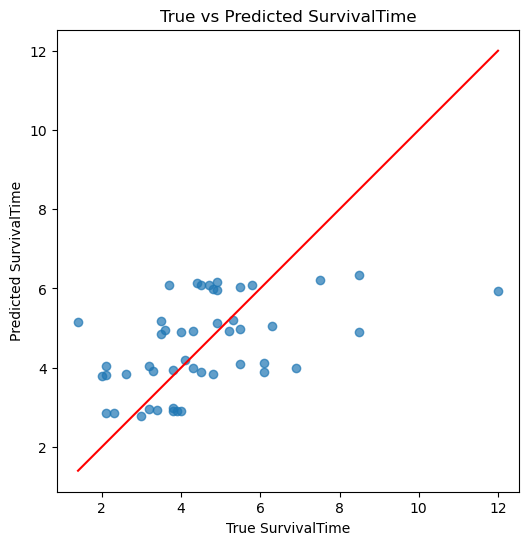

In [178]:
imp_simple_mean_model, imp_simple_mean_cmse = evaluate_imputation(X, y, c, model=linear_reg, method='simple', strategy='mean', show_metrics=True, show_plot=True)

##### Median

In [179]:
imp_simple_median_model, imp_simple_median_cmse = evaluate_imputation(X, y, c, model=linear_reg, method='simple', strategy='median', show_plot=False)

CV cMSE: 2.6621454948600958
Test cMSE: 2.4227557451652557


##### Most frequent

In [180]:
imp_simple_most_frequent_model, imp_simple_most_frequent_cmse = evaluate_imputation(X, y, c, model=linear_reg, method='simple', strategy='most_frequent', show_plot=False)

CV cMSE: 2.6621454948600958
Test cMSE: 2.4227557451652557


##### Mean strategy on best model from task 2 (KNN with k=29)

K = 29

In [181]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=29))
imp_simple_mean_model_knn, imp_simple_mean_cmse_knn = evaluate_imputation(X, y, c, model=knn_reg, method='simple', strategy='mean')

CV cMSE: 2.702614632877527
Test cMSE: 2.478961553705905


Determine best K for KNN regressor

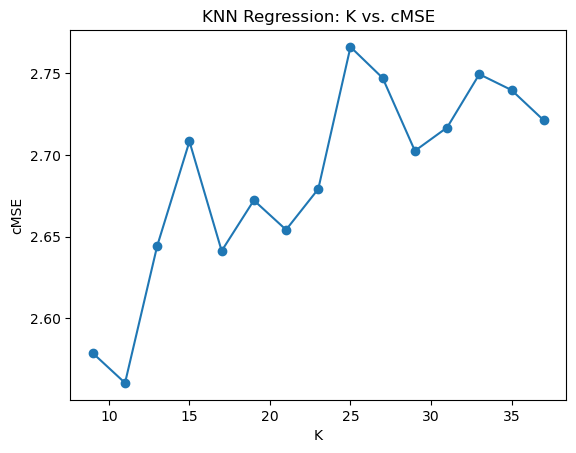

In [182]:
k_values = [9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37]
knn_scores = []

for k in k_values:
    knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, model=knn_reg, method='simple', strategy='mean', show_cmse=False, show_plot=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

In Simple imputation by mean, best K for KNN regressor is 9

In [183]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=9))
imp_simple_mean_model_knn, imp_simple_mean_cmse_knn = evaluate_imputation(X, y, c, model=knn_reg, method='simple', strategy='mean')

CV cMSE: 2.578738425925926
Test cMSE: 2.917798353909465


#### KNN imputer

##### Find best K for KNN imputer with cross validation

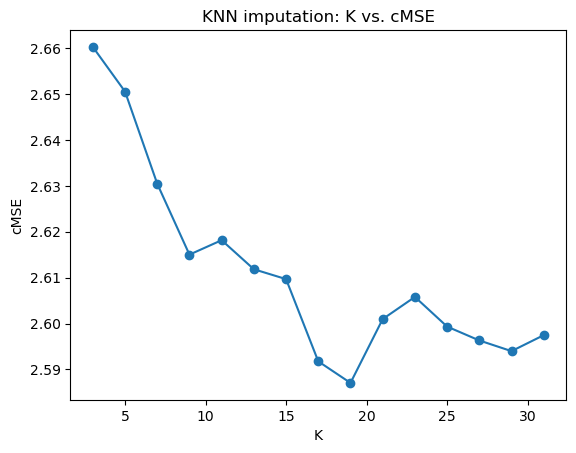

In [184]:
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31]
knn_scores = []

for k in k_values:
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, model=linear_reg, method='knn', n_neighbors=k, show_cmse=False, show_plot=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN imputation: K vs. cMSE")
plt.show()

Best K for KNN imputer is 19

In [185]:
imp_knn_model_knn, imp_knn_cmse_knn = evaluate_imputation(X, y, c, model=linear_reg, method='knn', n_neighbors=19)

CV cMSE: 2.587060500732423
Test cMSE: 2.4391886465016195


##### KNN imputation with k=19 on best model from task 2 (KNN with k=29)

K = 29

In [186]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=29))
imp_knn_model_knn, imp_knn_cmse_knn = evaluate_imputation(X, y, c, model=knn_reg, method='knn', n_neighbors=19)

CV cMSE: 2.6825702288941735
Test cMSE: 2.5268603844629407


Determine the best K for the KNN regressor

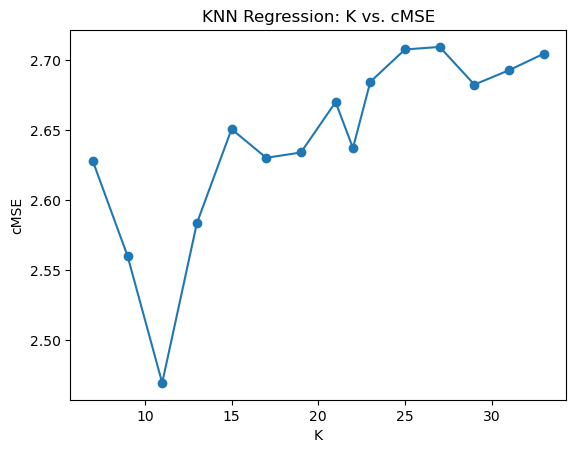

In [193]:
k_values = [7, 9, 11, 13, 15, 17, 19, 21, 22, 23, 25, 27, 29, 31, 33]
knn_scores = []

for k in k_values:
    knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, model=knn_reg, method='knn', n_neighbors=19, show_cmse=False, show_plot=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

In KNN imputation, best K for KNN regressor is 11

In [196]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))
imp_knn_model_knn, imp_knn_cmse_knn = evaluate_imputation(X, y, c, model=knn_reg, method='knn', n_neighbors=19)

CV cMSE: 2.4695781680440767
Test cMSE: 2.9259108126721762


#### Iterative imputer

##### Evaluation

In [197]:
imp_iterative_model, imp_iterative_cmse = evaluate_imputation(X, y, c, model=linear_reg, method='iterative')

CV cMSE: 2.614387285895696
Test cMSE: 2.4214396677414647


##### Iterative imputation on best model from task 2 (KNN with k = 29)

K = 29

In [198]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=29))
imp_iterative_model_knn, imp_iterative_cmse_knn = evaluate_imputation(X, y, c, model=knn_reg, method='iterative')

CV cMSE: 2.7072469530321044
Test cMSE: 2.4942513872374157


Determine best K for KNN regressor

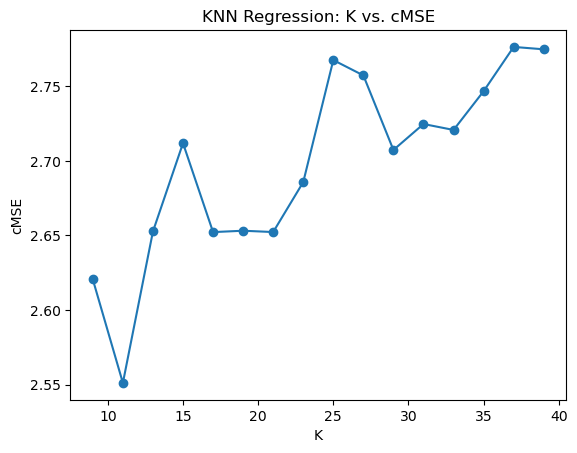

In [199]:
k_values = [9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39]
knn_scores = []

for k in k_values:
    knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, model=knn_reg, method='iterative', show_cmse=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

In Iterative imputation, best K for KNN regressor is 11

In [200]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))
imp_iterative_model_knn, imp_iterative_cmse_knn = evaluate_imputation(X, y, c, model=knn_reg, method='iterative')

CV cMSE: 2.551123450413223
Test cMSE: 2.858013085399449


## Task 3.2 Train models that do not require imputation

### Data preprocessing, no imputation

In [201]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df.dropna(subset=['SurvivalTime'])
print(f"Remaining points: {df.shape[0]}")

Remaining points: 240


In [202]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

# Split the data into train and test sets (with missing values)
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)

Feature matrix X shape: (240, 7)
Target vector y shape: (240,)
Censored vector c shape: (240,)


### Tree based methods

#### Function for training tree-based model

In [203]:
def train_tree_based_model(X, y, c, type='decision_tree', max_features='all', **kwargs):
    if max_features == 'all':
        max_features = X.shape[1]

    if type == 'decision_tree':
        model = DecisionTreeRegressor(random_state=30, max_features=max_features, **kwargs)
    elif type == 'random_forest':
        model = RandomForestRegressor(random_state=30, max_features=max_features, **kwargs)
    elif type == 'xgboost':
        model = XGBRegressor(**kwargs)
    elif type == 'catboost':
        model = CatBoostRegressor(**kwargs)
    elif type == 'hist_gradient_boost':
        model = HistGradientBoostingRegressor(random_state=30, **kwargs)
    else:
        raise ValueError(f"Unsupported model type: {type}")

    # Cross-validation predictions
    y_pred_cv = cross_val_predict(model, X, y, cv=10)
    
    # Calculate cMSE
    cMSE_cv = cMSE(y, y_pred_cv, c)
    print(f"{type} cMSE: {cMSE_cv}")
    
    # Train the model on the full training set
    model.fit(X, y)
    
    return model, cMSE_cv

#### Select best number of features for decision trees and random forest

Number of features used per step: all
decision_tree cMSE: 4.527864583333333
Decision Tree Test cMSE: 5.250416666666666
random_forest cMSE: 3.134326397313368
Random Forest Test cMSE: 2.9822441502835644

Number of features used per step: sqrt
decision_tree cMSE: 4.621276041666666
Decision Tree Test cMSE: 4.778333333333333
random_forest cMSE: 2.9571975444082743
Random Forest Test cMSE: 2.90924596644097

Number of features used per step: log2
decision_tree cMSE: 4.621276041666666
Decision Tree Test cMSE: 4.778333333333333
random_forest cMSE: 2.9571975444082743
Random Forest Test cMSE: 2.90924596644097



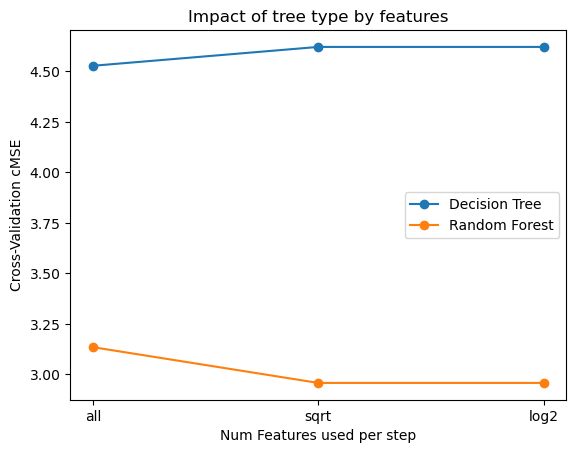

In [204]:
features = ['all', 'sqrt', 'log2']
decision_tree_cMSEs = []
random_forest_cMSEs = []
hist_gradient_boost_cMSEs = []

for n_features in features:
    print(f"Number of features used per step: {n_features}")
    
    # Train Decision Tree
    dt_model, dt_cMSE = train_tree_based_model(
        X_train, y_train, c_train, type='decision_tree', max_features=n_features)
    decision_tree_cMSEs.append(dt_cMSE)
    y_dt_test = dt_model.predict(X_test)
    cMSE_dt_test = cMSE(y_test, y_dt_test, c_test)
    print(f"Decision Tree Test cMSE: {cMSE_dt_test}")

    # Train Random Forest
    rf_model, rf_cMSE = train_tree_based_model(
        X_train, y_train, c_train, type='random_forest', max_features=n_features)
    random_forest_cMSEs.append(rf_cMSE)
    y_rf_test = rf_model.predict(X_test)
    cMSE_rf_test = cMSE(y_test, y_rf_test, c_test)
    print(f"Random Forest Test cMSE: {cMSE_rf_test}")
    
    print()
    
# Plot
plt.plot(features, decision_tree_cMSEs, label="Decision Tree", marker='o')
plt.plot(features, random_forest_cMSEs, label="Random Forest", marker='o')
plt.xlabel("Num Features used per step")
plt.ylabel("Cross-Validation cMSE")
plt.title("Impact of tree type by features")
plt.legend()
plt.show()

#### Try out all tree-based models

In [205]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
dt_scores = []
rf_scores = []
xgb_scores = []
cat_scores = []
hgb_scores = []

for d in depths:
    # Decision Tree
    dt_model, dt_cMSE = train_tree_based_model(X_train, y_train, c_train, type='decision_tree', max_depth=d, max_features='all')
    dt_scores.append(dt_cMSE)

    # Random Forest
    rf_model, rf_cMSE = train_tree_based_model(X_train, y_train, c_train, type='random_forest', max_depth=d, max_features='sqrt')
    rf_scores.append(rf_cMSE)

    # XGBoost
    xgb_model, xgb_cMSE = train_tree_based_model(X_train, y_train, c_train, type='xgboost', max_depth=d, learning_rate=0.05)
    xgb_scores.append(xgb_cMSE)
    
    # CatBoost
    cat_model, cat_cMSE = train_tree_based_model(X_train, y_train, c_train, type='catboost', max_depth=d, learning_rate=0.05, silent=True)
    cat_scores.append(cat_cMSE)
    
    # Histogram Gradient Boosting
    hgb_model, hgb_cMSE = train_tree_based_model(X_train, y_train, c_train, type='hist_gradient_boost', max_depth=d)
    hgb_scores.append(hgb_cMSE)

decision_tree cMSE: 2.9254363670299512
random_forest cMSE: 3.298682675696687
xgboost cMSE: 2.586056877004396
catboost cMSE: 2.8034087534416545
hist_gradient_boost cMSE: 2.6359027793166967
decision_tree cMSE: 2.6895748232413013
random_forest cMSE: 2.942482314892936
xgboost cMSE: 2.915154292593043
catboost cMSE: 3.439072767776084
hist_gradient_boost cMSE: 2.879887782500466
decision_tree cMSE: 2.813194757474547
random_forest cMSE: 2.8515584011644766
xgboost cMSE: 3.1826853469011476
catboost cMSE: 3.5332353567754637
hist_gradient_boost cMSE: 3.00461410230298
decision_tree cMSE: 3.1449155300870912
random_forest cMSE: 2.7866776197501815
xgboost cMSE: 3.4643738148000778
catboost cMSE: 3.4132222584809235
hist_gradient_boost cMSE: 3.0619724219173405
decision_tree cMSE: 3.435687623798741
random_forest cMSE: 2.7701954992349713
xgboost cMSE: 3.540517783718952
catboost cMSE: 3.2349652254181644
hist_gradient_boost cMSE: 3.1160275572397285
decision_tree cMSE: 4.135299757789866
random_forest cMSE: 2.7

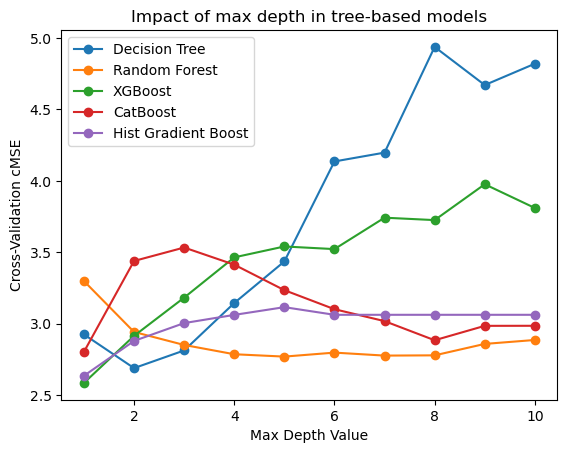

In [206]:
plt.plot(depths, dt_scores, label="Decision Tree", marker='o')
plt.plot(depths, rf_scores, label="Random Forest", marker='o')
plt.plot(depths, xgb_scores, label="XGBoost", marker='o')
plt.plot(depths, cat_scores, label="CatBoost", marker='o')
plt.plot(depths, hgb_scores, label="Hist Gradient Boost", marker='o')
plt.xlabel("Max Depth Value")
plt.ylabel("Cross-Validation cMSE")
plt.title("Impact of max depth in tree-based models")
plt.legend()
plt.show()

#### Run the best models

In [210]:
# Decision Tree
dt_model, dt_cMSE = train_tree_based_model(X_train, y_train, c_train, type='decision_tree', max_depth=2, max_features='all')
dt_scores.append(dt_cMSE)

# Random Forest
rf_model, rf_cMSE = train_tree_based_model(X_train, y_train, c_train, type='random_forest', max_depth=5, max_features='sqrt')
rf_scores.append(rf_cMSE)

# XGBoost
xgb_model, xgb_cMSE = train_tree_based_model(X_train, y_train, c_train, type='xgboost', max_depth=1, learning_rate=0.05)
dt_scores.append(xgb_cMSE)

# CatBoost
cat_model, cat_cMSE = train_tree_based_model(X_train, y_train, c_train, type='catboost', max_depth=1, learning_rate=0.01, silent=True)
cat_scores.append(cat_cMSE)

# Histogram Gradient Boosting
hgb_model, hgb_cMSE = train_tree_based_model(X_train, y_train, c_train, type='hist_gradient_boost', max_depth=1)
hgb_scores.append(hgb_cMSE)

decision_tree cMSE: 2.6895748232413013
random_forest cMSE: 2.7701954992349713
xgboost cMSE: 2.586056877004396
catboost cMSE: 2.6217057761904754
hist_gradient_boost cMSE: 2.6359027793166967


#### Compare CMSE across models

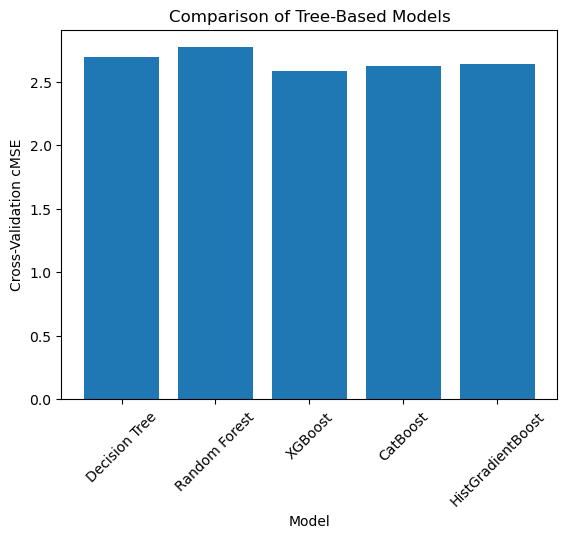

In [211]:
models = ['Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Tree-Based Models")
plt.xticks(rotation=45)
plt.show()

### CatBoost: Accelerated Failure Time (AFT) CatBoost applied to the assignment data.

#### Pre-processing

In [158]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
4,59.0,1,2,1.0,0,NaN,0.0,NaN,0


In [159]:
df = df.dropna(subset=['SurvivalTime'])

X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)
# Split the data into train and test sets (with missing values)
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=42)

df['y_lower'] = df['SurvivalTime']
df['y_upper'] = np.where(df['Censored'], df['SurvivalTime'], -1)
stratifying_column = df['Censored']
df.drop(columns=['Censored','SurvivalTime'], inplace=True)
# Replace NaNs with -1 to indicate a distinct "missing" category
df['TreatmentResponse'] = df['TreatmentResponse'].fillna(-1).astype(int)
df.head()

Feature matrix X shape: (240, 7)
Target vector y shape: (240,)
Censored vector c shape: (240,)


,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,y_lower,y_upper
0,65.0,0,2,1.0,0,0.0,0,4.2,-1.0
1,68.0,1,2,0.0,1,1.0,1,4.7,4.7
2,68.0,1,3,1.0,1,0.0,1,3.5,3.5
3,81.0,1,4,1.0,1,3.0,0,2.3,-1.0
5,47.0,1,4,1.0,1,NaN,0,2.6,-1.0


In [160]:
train, test = train_test_split(df, test_size=0.2, stratify=stratifying_column, random_state=42)

features = df.columns.difference(['y_lower', 'y_upper'], sort=False)
cat_features = ['Gender', 'Stage', 'TreatmentType', 'TreatmentResponse']

train_pool = Pool(train[features], label=train.loc[:,['y_lower','y_upper']], cat_features=cat_features)
test_pool = Pool(test[features], label=test.loc[:,['y_lower','y_upper']], cat_features=cat_features)

#### Models

In [161]:
model_normal = CatBoostRegressor(iterations=500,
                                 loss_function='SurvivalAft:dist=Normal',
                                 eval_metric='SurvivalAft',
                                 verbose=0
                                )

model_logistic = CatBoostRegressor(iterations=500,
                                 loss_function='SurvivalAft:dist=Logistic;scale=1.2',
                                 eval_metric='SurvivalAft',
                                 verbose=0)

model_extreme = CatBoostRegressor(iterations=500,
                                 loss_function='SurvivalAft:dist=Extreme;scale=2',
                                 eval_metric='SurvivalAft',
                                 verbose=0)

In [163]:
model_normal.fit(train_pool, eval_set=test_pool)
model_logistic.fit(train_pool, eval_set=test_pool)
model_extreme.fit(train_pool, eval_set=test_pool)

In [139]:
train_predictions = pd.DataFrame({'y_lower': train['y_lower'],
                                  'y_upper': train['y_upper'],
                                  'preds_normal': model_normal.predict(train_pool, prediction_type='Exponent'),
                                  'preds_logistic': model_logistic.predict(train_pool, prediction_type='Exponent'),
                                  'preds_extreme': model_extreme.predict(train_pool, prediction_type='Exponent')})
train_predictions['y_upper'] = np.where(train_predictions['y_upper']==-1, np.inf, train_predictions['y_upper'])

test_predictions = pd.DataFrame({'y_lower': test['y_lower'],
                                  'y_upper': test['y_upper'],
                                  'preds_normal': model_normal.predict(test_pool, prediction_type='Exponent'),
                                  'preds_logistic': model_logistic.predict(test_pool, prediction_type='Exponent'),
                                  'preds_extreme': model_extreme.predict(test_pool, prediction_type='Exponent')})
test_predictions['y_upper'] = np.where(test_predictions['y_upper']==-1, np.inf, test_predictions['y_upper'])

In [140]:
def interval_mae(y_true_lower, y_true_upper, y_pred):
    mae = np.where((y_true_lower <= y_pred) & (y_pred <= y_true_upper),
                   0,
                   np.minimum(np.abs(y_true_lower-y_pred),
                              np.abs(y_true_upper-y_pred))) 
    return mae.mean()

In [141]:
distributions = ['normal', 'logistic', 'extreme']
print('Interval MAE')
for dist in distributions:
    train_metric = interval_mae(train_predictions['y_lower'], train_predictions['y_upper'], train_predictions[f'preds_{dist}'])
    test_metric = interval_mae(test_predictions['y_lower'], test_predictions['y_upper'], test_predictions[f'preds_{dist}'])
    print(f'Train set. dist:{dist}: {train_metric:0.2f}')
    print(f'Test set. dist:{dist}: {test_metric:0.2f}')
    print('---------------------------')

Interval MAE
Train set. dist:normal: 0.83
Test set. dist:normal: 0.96
---------------------------
Train set. dist:logistic: 0.79
Test set. dist:logistic: 0.97
---------------------------
Train set. dist:extreme: 0.85
Test set. dist:extreme: 1.01
---------------------------


#### Test cMSE for all models

In [148]:
y_normal_pred_test = model_normal.predict(test_pool, prediction_type='Exponent')
cMSE_normal_test = cMSE(y_test, y_normal_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_normal_test}")

Test Set Censored Mean Squared Error (cMSE): 3.776131969461178


In [150]:
y_logistic_pred_test = model_logistic.predict(test_pool, prediction_type='Exponent')
cMSE_logistic_test = cMSE(y_test, y_logistic_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_logistic_test}")

Test Set Censored Mean Squared Error (cMSE): 3.6986800627152245


In [151]:
y_extreme_pred_test = model_extreme.predict(test_pool, prediction_type='Exponent')
cMSE_extreme_test = cMSE(y_test, y_extreme_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_extreme_test}")

Test Set Censored Mean Squared Error (cMSE): 4.002453790637691


## Task 3.3 Evaluation

### Pre-processing

In [212]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df.dropna(subset=['SurvivalTime'])
print(f"Remaining points after removing unlabeled rows: {df.shape[0]}")

Remaining points after removing unlabeled rows: 240


In [213]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (240, 7)
Target vector y shape: (240,)
Censored vector c shape: (240,)


### Imput and run models

#### Simple imputer with mean strategy

##### Linear regression

In [214]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
lr_model, lr_cMSE = evaluate_imputation(X, y, c, model=linear_reg, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.6095256381326184
Test cMSE: 2.421082353209675


##### Decision tree

In [215]:
dt_model, dt_cMSE = evaluate_imputation(X, y, c, model=dt_model, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.6895748232413017
Test cMSE: 2.4731535075895823


##### Random forest

In [216]:
rf_model, rf_cMSE = evaluate_imputation(X, y, c, model=rf_model, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.8072095521782656
Test cMSE: 2.912709887129646


##### XGBoost

In [217]:
xgb_model, xgb_cMSE = evaluate_imputation(X, y, c, model=xgb_model, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.625028623496577
Test cMSE: 2.478285557536139


##### CatBoost

In [218]:
cat_model, cat_cMSE = evaluate_imputation(X, y, c, model=cat_model, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.64102760488859
Test cMSE: 2.502387652597264


##### Histogram Gradient Boost

In [219]:
hgb_model, hgb_cMSE = evaluate_imputation(X, y, c, model=hgb_model, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.7088018607994937
Test cMSE: 2.5025824086784154


##### Compare models through CV cMSE

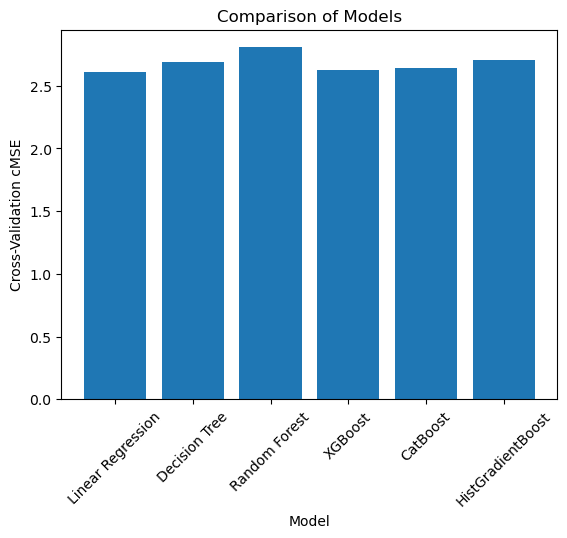

In [220]:
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [lr_cMSE, dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Models")
plt.xticks(rotation=45)
plt.show()

#### KNN imputer with K=19

##### Linear Regression

In [221]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
lr_model, lr_cMSE = evaluate_imputation(X, y, c, model=linear_reg, method='knn', n_neighbors=19)

CV cMSE: 2.587060500732423
Test cMSE: 2.4391886465016195


##### Decision Tree

In [222]:
dt_model, dt_cMSE = evaluate_imputation(X, y, c, model=dt_model, method='knn', n_neighbors=19)

CV cMSE: 2.531204378283932
Test cMSE: 2.4344804258114077


##### Random forest

In [223]:
rf_model, rf_cMSE = evaluate_imputation(X, y, c, model=rf_model, method='knn', n_neighbors=19)

CV cMSE: 2.744853821266215
Test cMSE: 3.0443563912347087


##### XGBoost

In [225]:
xgb_model, xgb_cMSE = evaluate_imputation(X, y, c, model=xgb_model, method='knn', n_neighbors=19)

CV cMSE: 2.5775852399598125
Test cMSE: 2.496134669140608


##### CatBoost

In [226]:
cat_model, cat_cMSE = evaluate_imputation(X, y, c, model=cat_model, method='knn', n_neighbors=19)

CV cMSE: 2.591520887376422
Test cMSE: 2.525594177921072


##### Histogram Gradient Boost

In [228]:
hgb_model, hgb_cMSE = evaluate_imputation(X, y, c, model=hgb_model, method='knn', n_neighbors=19)

CV cMSE: 2.668070624249363
Test cMSE: 2.5242629158668666


##### Compare models through CV cMSE

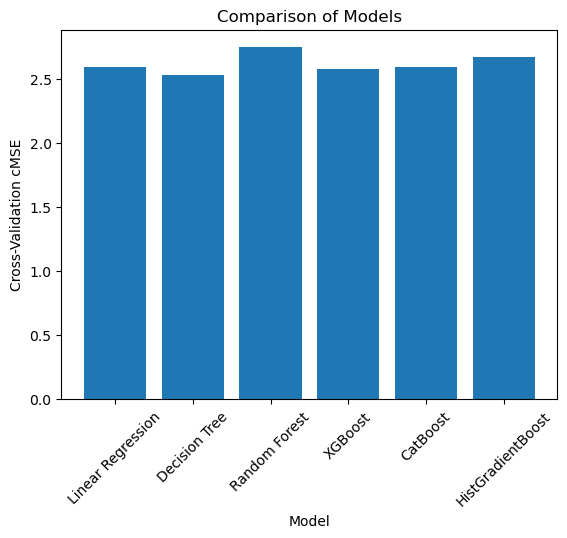

In [229]:
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [lr_cMSE, dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Models")
plt.xticks(rotation=45)
plt.show()

#### Iterative Imputer

##### Linear Regression

In [230]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
lr_model, lr_cMSE = evaluate_imputation(X, y, c, model=linear_reg, method='iterative')

CV cMSE: 2.614387285895696
Test cMSE: 2.4214396677414647


##### Decision Tree

In [231]:
dt_model, dt_cMSE = evaluate_imputation(X, y, c, model=dt_model, method='iterative')

CV cMSE: 2.631727043781623
Test cMSE: 2.4623309153759205


##### Random Forest

In [232]:
rf_model, rf_cMSE = evaluate_imputation(X, y, c, model=rf_model, method='iterative')

CV cMSE: 2.78810945387167
Test cMSE: 2.9304056898316895


##### XGBoost

In [233]:
xgb_model, xgb_cMSE = evaluate_imputation(X, y, c, model=xgb_model, method='iterative')

CV cMSE: 2.634924350710497
Test cMSE: 2.4769176085306777


##### CatBoost

In [234]:
cat_model, cat_cMSE = evaluate_imputation(X, y, c, model=cat_model, method='iterative')

CV cMSE: 2.6420449353028275
Test cMSE: 2.4940162553257506


##### Histogram Gradient Boost

In [235]:
hgb_model, hgb_cMSE = evaluate_imputation(X, y, c, model=hgb_model, method='iterative')

CV cMSE: 2.7292688207885925
Test cMSE: 2.521130259267931


##### Compare models through CV cMSE

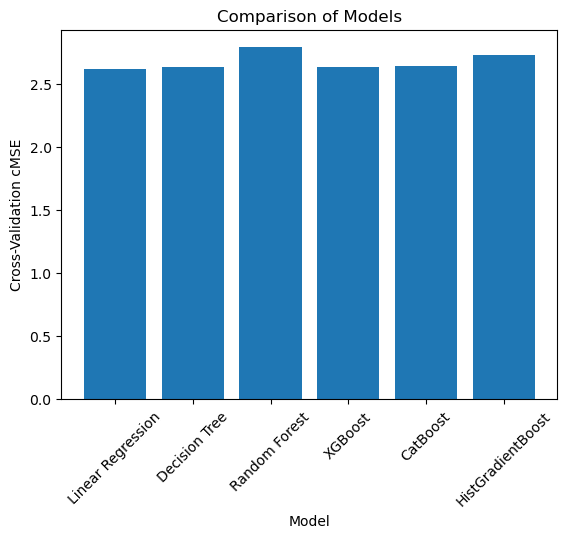

In [236]:
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [lr_cMSE, dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Models")
plt.xticks(rotation=45)
plt.show()

### Submission of best models

#### Pre-processing

In [296]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
# drop unlabeled rows (missing Survival Time)
df = df.dropna(subset=['SurvivalTime'])

X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (240, 7)
Target vector y shape: (240,)
Censored vector c shape: (240,)


Decision tree

In [302]:
dt_model_sm, dt_cMSE = evaluate_imputation(X, y, c, model=dt_model, method='simple', strategy='mean', show_metrics=False, show_plot=False)

CV cMSE: 2.4042087993372374
Test cMSE: 3.175108009165726


#### Load Kaggle dataset and impute it

In [300]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
X_kaggle_df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse
0,71.0,1,4,NaN,1,1.0,1.0
1,57.0,1,4,0.0,0,NaN,0.0
2,66.0,0,2,0.0,0,0.0,1.0
3,73.0,0,3,NaN,1,1.0,1.0
4,53.0,1,4,0.0,0,0.0,0.0


Impute dataset

In [ ]:
imputer_sm = SimpleImputer(strategy='mean')
imputer_knn = KNNImputer(n_neighbors=19)
imputer_iter = IterativeImputer()

X_imp_sm = imputer_sm.fit_transform(X_kaggle_df)
X_imp_knn = imputer_knn.fit_transform(X_kaggle_df)   
X_imp_iter = imputer_iter.fit_transform(X)

#### Make prediction

In [ ]:
y_dt_sm_pred = dt_model_sm.predict(X_imp_sm)
save_predictions(y_dt_sm_pred, './submissions/handle-missing-submission-01.csv')